In [26]:
import numpy as np
from geopandas import read_file as gpd_read_file
from rasterio import open as rasterio_open
from rasterio.warp import reproject, Resampling
from rasterio.features import rasterize
from rasterio.fill import fillnodata
from scipy.ndimage import gaussian_filter, maximum_filter, binary_dilation
from matplotlib import pyplot as plt

In [ ]:
from skimage.morphology import closing, disk
from scipy.ndimage import gaussian_filter, maximum_filter, binary_dilation

In [96]:
def detect_crevasses(dem, radius, enlarge=None, depth=None):
    
    if enlarge is None:
        enlarge = max(1, .1 * radius)

    if depth is None:
        depth = .05 * radius

    # fill crevasses using closing operation with circular kernel
    dem_closed = closing(dem, footprint=disk(radius))

    # detect crevasses by subtracting original
    mask = (dem_closed - dem) > depth

    # enlarge True regions in mask (detected crevasses)
    mask = binary_dilation(mask, structure=disk(enlarge))

    return mask



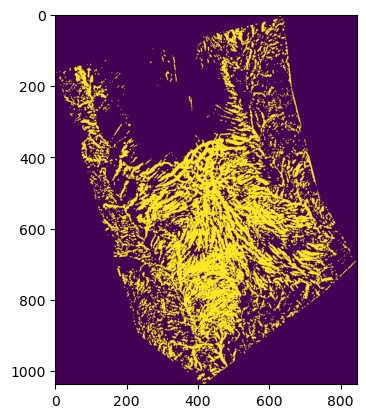

In [109]:
input_tif = "C:/Users/jkolar/Desktop/planpinceuxDEM/DEM_Planpi_20260901_32632_1m.tif"
output_tif = "C:/Users/jkolar/Desktop/planpinceuxDEM/DEM_Planpi_20260901_32632_1m_closingtest5.tif"

with rasterio_open(input_tif) as src:
    data = src.read()  # shape: (bands, rows, cols)
    transform = src.transform
    crs = src.crs
    height = src.height
    width = src.width
    profile = src.profile.copy()
    nodata = src.nodata

if nodata is not None:
    data[data == nodata] = np.nan

mask = detect_crevasses(data[0], radius=5, depth=.5, enlarge=None)

# fill masked values
data_filled = fillnodata(data, mask=~mask, max_search_distance=20,
                    smoothing_iterations=1)

with rasterio_open(output_tif, "w", **profile) as dst:
    dst.write(data_filled)

plt.imshow(mask)

# implementations
- output mask
- use closing for crevasse detection
- auto filename

In [1]:
from demprepfly import prepdem

input_tif = "C:/Users/jkolar/Desktop/planpinceuxDEM/DEM_Planpi_20260901_32632_1m.tif"
output_tif = "C:/Users/jkolar/Desktop/planpinceuxDEM/prepdem_test8.tif"
mask_shp = "C:/Users/jkolar/Desktop/planpinceuxDEM/crevasses.shp"

prepdem(input_tif, output_tif, fill_mask=mask_shp, detect_maxsize=21, detect_mindepth=.5, smoothing_radius=3)

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(1037, 846), dtype=float32)